In [2]:
from pathlib import Path
import csv

CURRENT_DIR = Path.cwd().resolve()

ROOT = (
    CURRENT_DIR
    if (CURRENT_DIR / "dataset" / "raw" / "books_with_categories.csv").is_file()
    else CURRENT_DIR.parent
)

DATA_PATH = ROOT / "dataset" / "raw" / "books_with_categories.csv"

if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f"CSV asli belum ditemukan: {DATA_PATH}"
    )

with DATA_PATH.open("r", encoding="utf-8-sig", newline="") as f:
    columns = next(csv.reader(f))

print("Project :", ROOT)
print("Dataset :", DATA_PATH)
print("Kolom   :", columns)
print("[OK] CSV asli ditemukan dan tidak diubah")

Project : D:\Project\SmartLibrary_AI
Dataset : D:\Project\SmartLibrary_AI\dataset\raw\books_with_categories.csv
Kolom   : ['isbn13', 'isbn10', 'title', 'authors', 'categories', 'thumbnail', 'description', 'published_year', 'average_rating', 'num_pages', 'ratings_count', 'title_and_subtitle', 'tagged_description', 'simple_categories']
[OK] CSV asli ditemukan dan tidak diubah


In [3]:
import pandas as pd

# Membaca dataset asli
df = pd.read_csv(
    DATA_PATH,
    dtype={
        "isbn13": "string",
        "isbn10": "string"
    }
)

# Menampilkan ukuran dataset
print("Jumlah baris :", df.shape[0])
print("Jumlah kolom :", df.shape[1])

# Menampilkan lima buku pertama
display(df.head())

Jumlah baris : 5197
Jumlah kolom : 14


,isbn13,isbn10,title,authors,categories,thumbnail,description,published_year,average_rating,num_pages,ratings_count,title_and_subtitle,tagged_description,simple_categories
0,9780002005883,0002005883,Gilead,Marilynne Robinson,Fiction,http://books.google.com/books/content?id=KQZCP...,A NOVEL THAT READERS and critics have been eag...,2004.0,3.85,247.0,361.0,Gilead,9780002005883 A NOVEL THAT READERS and critics...,Fiction
1,9780002261982,0002261987,Spider's Web,Charles Osborne;Agatha Christie,Detective and mystery stories,http://books.google.com/books/content?id=gA5GP...,A new 'Christie for Christmas' -- a full-lengt...,2000.0,3.83,241.0,5164.0,Spider's Web: A Novel,9780002261982 A new 'Christie for Christmas' -...,Fiction
2,9780006178736,0006178731,Rage of angels,Sidney Sheldon,Fiction,http://books.google.com/books/content?id=FKo2T...,"A memorable, mesmerizing heroine Jennifer -- b...",1993.0,3.93,512.0,29532.0,Rage of angels,"9780006178736 A memorable, mesmerizing heroine...",Fiction
3,9780006280897,0006280897,The Four Loves,Clive Staples Lewis,Christian life,http://books.google.com/books/content?id=XhQ5X...,Lewis' work on the nature of love divides love...,2002.0,4.15,170.0,33684.0,The Four Loves,9780006280897 Lewis' work on the nature of lov...,Nonfiction
4,9780006280934,0006280935,The Problem of Pain,Clive Staples Lewis,Christian life,http://books.google.com/books/content?id=Kk-uV...,"""In The Problem of Pain, C.S. Lewis, one of th...",2002.0,4.09,176.0,37569.0,The Problem of Pain,"9780006280934 ""In The Problem of Pain, C.S. Le...",Nonfiction


In [4]:
# Informasi struktur dataset
df.info()

# Jumlah nilai kosong pada setiap kolom
missing_values = df.isna().sum()

# Persentase nilai kosong
missing_percentage = (
    missing_values / len(df) * 100
).round(2)

# Tabel ringkasan missing values
missing_summary = pd.DataFrame({
    "Jumlah Kosong": missing_values,
    "Persentase (%)": missing_percentage
})

display(missing_summary)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5197 entries, 0 to 5196
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   isbn13              5197 non-null   string 
 1   isbn10              5197 non-null   string 
 2   title               5197 non-null   object 
 3   authors             5165 non-null   object 
 4   categories          5167 non-null   object 
 5   thumbnail           5031 non-null   object 
 6   description         5197 non-null   object 
 7   published_year      5197 non-null   float64
 8   average_rating      5197 non-null   float64
 9   num_pages           5197 non-null   float64
 10  ratings_count       5197 non-null   float64
 11  title_and_subtitle  5197 non-null   object 
 12  tagged_description  5197 non-null   object 
 13  simple_categories   5197 non-null   object 
dtypes: float64(4), object(8), string(2)
memory usage: 568.6+ KB


,Jumlah Kosong,Persentase (%)
isbn13,0,0.00
isbn10,0,0.00
title,0,0.00
authors,32,0.62
categories,30,0.58
thumbnail,166,3.19
description,0,0.00
published_year,0,0.00
average_rating,0,0.00
num_pages,0,0.00


In [5]:
# Membuat salinan untuk pemeriksaan
df_check = df.copy()

# Normalisasi judul untuk pemeriksaan duplikasi
df_check["title_norm"] = (
    df_check["title"]
    .astype("string")
    .str.strip()
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
)

# Normalisasi nama penulis
df_check["authors_norm"] = (
    df_check["authors"]
    .astype("string")
    .str.strip()
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
)

# Pemeriksaan duplikasi
duplicate_isbn13 = df_check.duplicated(
    subset=["isbn13"]
).sum()

duplicate_isbn10 = df_check.duplicated(
    subset=["isbn10"]
).sum()

duplicate_title = df_check.duplicated(
    subset=["title_norm"],
    keep=False
).sum()

duplicate_title_author = df_check.loc[
    df_check["authors_norm"].notna()
].duplicated(
    subset=["title_norm", "authors_norm"],
    keep=False
).sum()

# Ringkasan hasil
duplicate_summary = pd.DataFrame({
    "Jenis Pemeriksaan": [
        "ISBN-13 sama",
        "ISBN-10 sama",
        "Judul sama",
        "Judul dan penulis sama"
    ],
    "Jumlah Baris Terindikasi": [
        duplicate_isbn13,
        duplicate_isbn10,
        duplicate_title,
        duplicate_title_author
    ]
})

display(duplicate_summary)

,Jenis Pemeriksaan,Jumlah Baris Terindikasi
0,ISBN-13 sama,0
1,ISBN-10 sama,0
2,Judul sama,428
3,Judul dan penulis sama,194


In [6]:
# Mengambil buku dengan judul yang berulang
df_duplicate_title = df_check[
    df_check.duplicated(
        subset=["title_norm"],
        keep=False
    )
].copy()

# Mengurutkan berdasarkan judul
df_duplicate_title = df_duplicate_title.sort_values(
    by="title_norm"
)

# Menampilkan beberapa contoh
display(
    df_duplicate_title[
        ["title", "authors", "isbn13", "published_year"]
    ].head(20)
)

,title,authors,isbn13,published_year
4142,"20,000 Leagues Under the Sea",Jules Verne,9780861366583,1987.0
3563,"20,000 Leagues Under the Sea",Jules Verne,9780760728505,2002.0
1075,"20,000 Leagues Under the Sea",Jules Verne;Pauline Francis,9780237526887,2004.0
2707,A Brief History of Time,Stephen Hawking,9780553380163,1998.0
2656,A Brief History of Time,Stephen Hawking,9780553053401,1998.0
2874,A Brief History of Time,Stephen Hawking,9780593043165,1998.0
4310,A Fine Balance,Rohinton Mistry,9781400030651,1997.0
3060,A fine balance,Rohinton Mistry,9780679446088,1996.0
4439,A Little Princess,Frances Hodgson Burnett,9781402714542,2004.0
825,A Little Princess,Frances Hodgson Burnett,9780142437018,2002.0


In [7]:
# =========================================================
# CELL 6 - PENANGANAN MISSING VALUES
# =========================================================

# Membuat salinan dataset asli
df_clean = df.copy()

# 1. Membersihkan spasi dan teks kosong
text_columns = [
    "title",
    "authors",
    "categories",
    "description",
    "thumbnail",
    "simple_categories"
]

for col in text_columns:
    df_clean[col] = (
        df_clean[col]
        .astype("string")
        .str.strip()
        .replace("", pd.NA)
    )

# 2. Menandai data yang awalnya kosong
df_clean["author_missing"] = (
    df_clean["authors"].isna()
)

df_clean["category_missing"] = (
    df_clean["categories"].isna()
)

# 3. Menangani penulis yang kosong
df_clean["authors"] = (
    df_clean["authors"]
    .fillna("Penulis tidak diketahui")
)

# 4. Menangani kategori yang kosong
df_clean["categories"] = (
    df_clean["categories"]
    .fillna(df_clean["simple_categories"])
)

# 5. Thumbnail tetap dibiarkan kosong
# Karena tidak digunakan dalam perhitungan TF-IDF

print("Penanganan missing values selesai.")
print("Jumlah buku:", len(df_clean))

Penanganan missing values selesai.
Jumlah buku: 5197


In [8]:
# =========================================================
# CELL 7 - VALIDASI PENANGANAN MISSING VALUES
# =========================================================

# Membandingkan missing values sebelum dan sesudah
missing_comparison = pd.DataFrame({
    "Sebelum": df.isna().sum(),
    "Sesudah": df_clean.isna().sum()
})

display(
    missing_comparison.loc[
        ["authors", "categories", "thumbnail"]
    ]
)

# Menampilkan jumlah data yang ditangani
print("Penulis yang dilengkapi:",
      df_clean["author_missing"].sum())

print("Kategori yang dilengkapi:",
      df_clean["category_missing"].sum())

print("Thumbnail masih kosong:",
      df_clean["thumbnail"].isna().sum())

# Memastikan jumlah baris tidak berubah
assert len(df_clean) == len(df), \
    "Jumlah buku berubah!"

# Memastikan kolom penting lengkap
assert df_clean["title"].notna().all()
assert df_clean["description"].notna().all()
assert df_clean["authors"].notna().all()
assert df_clean["categories"].notna().all()

print("\n[OK] Validasi berhasil.")
print("[OK] Jumlah buku tetap:", len(df_clean))

,Sebelum,Sesudah
authors,32.0,0
categories,30.0,0
thumbnail,166.0,166


Penulis yang dilengkapi: 32
Kategori yang dilengkapi: 30
Thumbnail masih kosong: 166

[OK] Validasi berhasil.
[OK] Jumlah buku tetap: 5197


In [9]:
# =========================================================
# CELL 8 - NORMALISASI TEKS
# =========================================================

import re
import html
import unicodedata

def normalize_text(text):
    """
    Melakukan normalisasi teks untuk kebutuhan NLP.

    Proses:
    1. Menangani nilai kosong
    2. Mengubah HTML entities
    3. Normalisasi karakter Unicode
    4. Menghapus URL dan HTML tags
    5. Mengubah teks menjadi huruf kecil
    6. Menghapus tanda baca
    7. Merapikan spasi
    """

    if pd.isna(text):
        return ""

    # Mengubah teks menjadi string
    text = str(text)

    # Membersihkan HTML entities
    text = html.unescape(text)

    # Normalisasi Unicode
    text = unicodedata.normalize("NFKC", text)

    # Menghapus URL
    text = re.sub(
        r"https?://\S+|www\.\S+",
        " ",
        text,
        flags=re.IGNORECASE
    )

    # Menghapus HTML tags
    text = re.sub(r"<[^>]*>", " ", text)

    # Mengubah menjadi huruf kecil
    text = text.casefold()

    # Menghapus tanda baca
    text = re.sub(r"[^\w\s]", " ", text)

    # Mengganti underscore menjadi spasi
    text = re.sub(r"_+", " ", text)

    # Merapikan spasi
    text = re.sub(r"\s+", " ", text).strip()

    return text


# Kolom teks yang akan dinormalisasi
nlp_columns = [
    "title",
    "categories",
    "description"
]

# Membuat kolom baru untuk NLP
for column in nlp_columns:
    df_clean[f"{column}_nlp"] = (
        df_clean[column].map(normalize_text)
    )

print("[OK] Normalisasi teks selesai.")
print("Jumlah buku:", len(df_clean))
print("Jumlah kolom:", len(df_clean.columns))

[OK] Normalisasi teks selesai.
Jumlah buku: 5197
Jumlah kolom: 19


In [10]:
# =========================================================
# CELL 9 - HASIL NORMALISASI TEKS
# =========================================================

# Menampilkan perbandingan judul
print("PERBANDINGAN JUDUL")
display(
    df_clean[
        ["title", "title_nlp"]
    ].head(10)
)

# Menampilkan perbandingan kategori
print("\nPERBANDINGAN KATEGORI")
display(
    df_clean[
        ["categories", "categories_nlp"]
    ].head(10)
)

# Menampilkan contoh deskripsi
print("\nCONTOH DESKRIPSI")

contoh = df_clean.iloc[1]

print("Judul:", contoh["title"])

print("\nDeskripsi asli:")
print(contoh["description"][:400])

print("\nDeskripsi setelah normalisasi:")
print(contoh["description_nlp"][:400])

PERBANDINGAN JUDUL


,title,title_nlp
0,Gilead,gilead
1,Spider's Web,spider s web
2,Rage of angels,rage of angels
3,The Four Loves,the four loves
4,The Problem of Pain,the problem of pain
5,Empires of the Monsoon,empires of the monsoon
6,The Gap Into Madness,the gap into madness
7,Master of the Game,master of the game
8,Warhost of Vastmark,warhost of vastmark
9,The Once and Future King,the once and future king



PERBANDINGAN KATEGORI


,categories,categories_nlp
0,Fiction,fiction
1,Detective and mystery stories,detective and mystery stories
2,Fiction,fiction
3,Christian life,christian life
4,Christian life,christian life
5,"Africa, East",africa east
6,"Hyland, Morn (Fictitious character)",hyland morn fictitious character
7,Adventure stories,adventure stories
8,Fiction,fiction
9,Arthurian romances,arthurian romances



CONTOH DESKRIPSI
Judul: Spider's Web

Deskripsi asli:
A new 'Christie for Christmas' -- a full-length novel adapted from her acclaimed play by Charles Osborne Following BLACK COFFEE and THE UNEXPECTED GUEST comes the final Agatha Christie play novelisation, bringing her superb storytelling to a new legion of fans. Clarissa, the wife of a Foreign Office diplomat, is given to daydreaming. 'Supposing I were to come down one morning and find a dead body 

Deskripsi setelah normalisasi:
a new christie for christmas a full length novel adapted from her acclaimed play by charles osborne following black coffee and the unexpected guest comes the final agatha christie play novelisation bringing her superb storytelling to a new legion of fans clarissa the wife of a foreign office diplomat is given to daydreaming supposing i were to come down one morning and find a dead body in the libr


In [11]:
# =========================================================
# CELL 10 - VALIDASI NORMALISASI TEKS
# =========================================================

# Memeriksa nilai kosong pada kolom NLP
validation = pd.DataFrame({
    "Kolom": [
        "title_nlp",
        "categories_nlp",
        "description_nlp"
    ],
    "Jumlah Teks Kosong": [
        (df_clean["title_nlp"] == "").sum(),
        (df_clean["categories_nlp"] == "").sum(),
        (df_clean["description_nlp"] == "").sum()
    ]
})

display(validation)

# Memastikan jumlah data tetap
assert len(df_clean) == len(df), \
    "Jumlah buku berubah!"

# Memastikan seluruh teks NLP tersedia
for column in nlp_columns:
    nlp_column = f"{column}_nlp"

    assert df_clean[nlp_column].notna().all(), \
        f"Ada nilai kosong pada {nlp_column}"

    assert (df_clean[nlp_column] != "").all(), \
        f"Ada teks kosong pada {nlp_column}"

print("\n[OK] Seluruh validasi berhasil.")
print("[OK] Jumlah buku tetap:", len(df_clean))
print("[OK] Kolom NLP siap digunakan.")

,Kolom,Jumlah Teks Kosong
0,title_nlp,0
1,categories_nlp,0
2,description_nlp,0



[OK] Seluruh validasi berhasil.
[OK] Jumlah buku tetap: 5197
[OK] Kolom NLP siap digunakan.


In [12]:
# =========================================================
# CELL 11 - IDENTIFIKASI BUKU BERULANG
# =========================================================

# Membuat salinan dataset yang sudah dibersihkan
df_catalog = df_clean.copy()

# Normalisasi nama penulis
df_catalog["authors_nlp"] = (
    df_catalog["authors"].map(normalize_text)
)

# Membuat identitas kelompok buku
# Berdasarkan judul dan penulis
df_catalog["book_key"] = (
    df_catalog["title_nlp"]
    + " | "
    + df_catalog["authors_nlp"]
)

# Jika penulis tidak diketahui,
# gunakan ISBN agar buku berbeda tidak digabung
mask_unknown = df_catalog["author_missing"]

df_catalog.loc[mask_unknown, "book_key"] = (
    df_catalog.loc[mask_unknown, "title_nlp"]
    + " | isbn:"
    + df_catalog.loc[mask_unknown, "isbn13"].astype(str)
)

# Menghitung jumlah edisi pada setiap kelompok
book_counts = (
    df_catalog.groupby("book_key")
    .size()
    .rename("jumlah_edisi")
)

# Mengidentifikasi kelompok berulang
duplicate_groups = book_counts[
    book_counts > 1
]

print("Total buku:", len(df_catalog))
print("Buku unik berdasarkan judul dan penulis:",
      df_catalog["book_key"].nunique())

print("Kelompok buku berulang:",
      len(duplicate_groups))

print("Baris dalam kelompok berulang:",
      book_counts[book_counts > 1].sum())

print("Edisi tambahan:",
      len(df_catalog) - df_catalog["book_key"].nunique())

Total buku: 5197
Buku unik berdasarkan judul dan penulis: 5094
Kelompok buku berulang: 95
Baris dalam kelompok berulang: 198
Edisi tambahan: 103


In [13]:
# =========================================================
# CELL 12 - PEMILIHAN EDISI REPRESENTATIF
# =========================================================

df_candidates = df_catalog.copy()

# Mengukur kelengkapan metadata
df_candidates["_has_category"] = (
    ~df_candidates["category_missing"]
).astype(int)

df_candidates["_has_cover"] = (
    df_candidates["thumbnail"].notna()
).astype(int)

df_candidates["_desc_length"] = (
    df_candidates["description_nlp"].str.len()
)

df_candidates["_rating_count"] = (
    pd.to_numeric(
        df_candidates["ratings_count"],
        errors="coerce"
    ).fillna(0)
)

# Mengurutkan kandidat berdasarkan kriteria
df_candidates = df_candidates.sort_values(
    by=[
        "book_key",
        "_has_category",
        "_desc_length",
        "_rating_count",
        "_has_cover",
        "isbn13"
    ],
    ascending=[
        True,
        False,
        False,
        False,
        False,
        True
    ],
    kind="mergesort"
)

# Memilih satu edisi per kelompok buku
df_recommendation = (
    df_candidates
    .drop_duplicates(
        subset="book_key",
        keep="first"
    )
    .copy()
)

# Menyimpan edisi alternatif secara terpisah
df_other_editions = df_candidates[
    ~df_candidates["isbn13"].isin(
        df_recommendation["isbn13"]
    )
].copy()

# Menghapus kolom sementara
temporary_columns = [
    "_has_category",
    "_has_cover",
    "_desc_length",
    "_rating_count"
]

df_recommendation = (
    df_recommendation
    .drop(columns=temporary_columns)
    .reset_index(drop=True)
)

df_other_editions = (
    df_other_editions
    .drop(columns=temporary_columns)
    .reset_index(drop=True)
)

print("[OK] Pemilihan edisi selesai")
print("Buku untuk rekomendasi:", len(df_recommendation))
print("Edisi alternatif:", len(df_other_editions))

[OK] Pemilihan edisi selesai
Buku untuk rekomendasi: 5094
Edisi alternatif: 103


In [14]:
# =========================================================
# CELL 13 - VALIDASI PENANGANAN DUPLIKASI
# =========================================================

# Memastikan jumlah data konsisten
assert (
    len(df_recommendation) + len(df_other_editions)
    == len(df_catalog)
), "Jumlah data tidak konsisten!"

# Memastikan identitas kelompok buku unik
assert df_recommendation["book_key"].is_unique, \
    "Masih terdapat kelompok buku yang berulang!"

# Memastikan ISBN unik
assert df_recommendation["isbn13"].is_unique, \
    "Masih terdapat ISBN duplikat!"

# Memastikan deskripsi tersedia
assert (
    df_recommendation["description_nlp"] != ""
).all(), "Ditemukan deskripsi kosong!"

# Menampilkan contoh hasil
display(
    df_recommendation[
        [
            "isbn13",
            "title",
            "authors",
            "categories",
            "published_year"
        ]
    ].head(10)
)

print("\n[OK] Validasi berhasil")
print("Jumlah buku rekomendasi:", len(df_recommendation))
print("Jumlah edisi alternatif:", len(df_other_editions))
print("Dataset asli tetap:", len(df))

,isbn13,title,authors,categories,published_year
0,9780425197455,10 Lb. Penalty,Dick Francis,Fiction,2004.0
1,9781579905088,1000 Rings,Marthe Le Van,Crafts & Hobbies,2004.0
2,9780486256078,1001 Illuminated Initial Letters,Owen Jones,Design,1988.0
3,9780060540944,1421,Gavin Menzies,History,2004.0
4,9781400032051,1491,Charles C. Mann,History,2006.0
5,9781416509387,1635: Cannon Law,Eric Flint;Andrew Dennis,Fiction,2006.0
6,9780440322276,18 Best Stories,Edgar Allan Poe,Fiction,1965.0
7,9780345455826,1968,Mark Kurlansky,History,2005.0
8,9780452284234,1984,George Orwell,London (England),2003.0
9,9780446696616,1st to Die,James Patterson,Fiction,2005.0



[OK] Validasi berhasil
Jumlah buku rekomendasi: 5094
Jumlah edisi alternatif: 103
Dataset asli tetap: 5197


In [15]:
# =========================================================
# CELL 14 - PEMBUATAN COMBINED_TEXT
# =========================================================

# Kolom teks yang digunakan sebagai fitur rekomendasi
feature_columns = [
    "title_nlp",
    "categories_nlp",
    "description_nlp"
]

# Memastikan semua kolom tersedia
for column in feature_columns:
    assert column in df_recommendation.columns, (
        f"Kolom {column} tidak ditemukan!"
    )

# Menggabungkan judul, kategori, dan deskripsi
df_recommendation["combined_text"] = (
    df_recommendation[feature_columns]
    .fillna("")
    .agg(" ".join, axis=1)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

print("[OK] combined_text berhasil dibuat.")
print("Jumlah buku:", len(df_recommendation))
print("Jumlah kolom:", len(df_recommendation.columns))

[OK] combined_text berhasil dibuat.
Jumlah buku: 5094
Jumlah kolom: 22


In [16]:
# =========================================================
# CELL 15 - PEMERIKSAAN COMBINED_TEXT
# =========================================================

# Menampilkan lima contoh buku
preview = df_recommendation[
    [
        "title",
        "categories",
        "combined_text"
    ]
].head(5).copy()

# Membatasi panjang teks untuk ditampilkan
preview["combined_text"] = (
    preview["combined_text"].str.slice(0, 250) + "..."
)

display(preview)

# Mengukur panjang teks setiap buku
df_recommendation["text_length"] = (
    df_recommendation["combined_text"].str.len()
)

df_recommendation["word_count"] = (
    df_recommendation["combined_text"]
    .str.split()
    .str.len()
)

# Statistik panjang teks
print("\nSTATISTIK PANJANG TEKS")

display(
    df_recommendation[
        ["text_length", "word_count"]
    ].describe().round(2)
)

,title,categories,combined_text
0,10 Lb. Penalty,Fiction,10 lb penalty fiction entering the political a...
1,1000 Rings,Crafts & Hobbies,1000 rings crafts hobbies an extensive and div...
2,1001 Illuminated Initial Letters,Design,1001 illuminated initial letters design the il...
3,1421,History,1421 history based on 15 years of in depth res...
4,1491,History,1491 history describes how recent archaeologic...



STATISTIK PANJANG TEKS


,text_length,word_count
count,5094.00,5094.00
mean,511.05,86.58
std,414.65,70.63
min,141.00,25.00
25%,247.00,41.00
50%,318.00,54.00
75%,669.00,114.00
max,5665.00,942.00


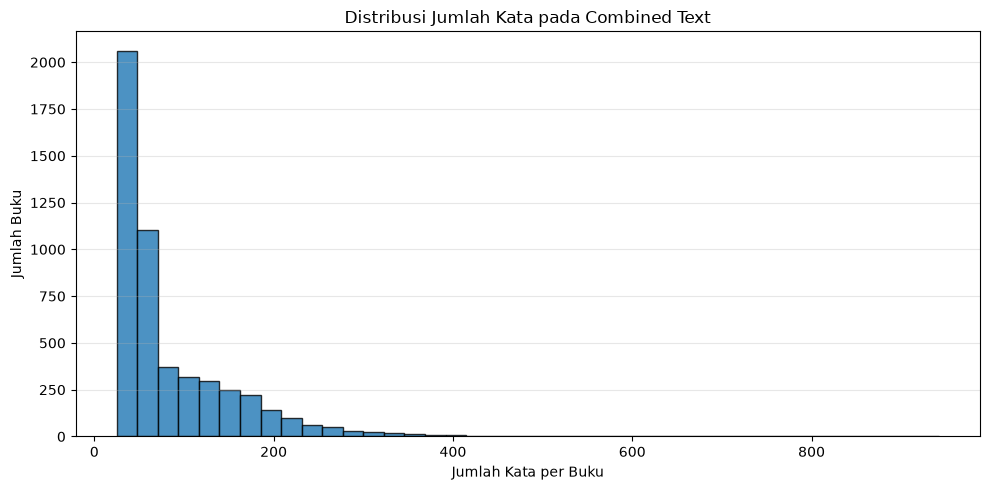

In [17]:
# =========================================================
# CELL 16 - DISTRIBUSI PANJANG TEKS
# =========================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    df_recommendation["word_count"],
    bins=40,
    edgecolor="black",
    alpha=0.8
)

plt.title(
    "Distribusi Jumlah Kata pada Combined Text"
)

plt.xlabel("Jumlah Kata per Buku")
plt.ylabel("Jumlah Buku")

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [18]:
# =========================================================
# CELL 17 - VALIDASI COMBINED_TEXT
# =========================================================

# Memastikan jumlah buku tidak berubah
assert len(df_recommendation) == (
    df_catalog["book_key"].nunique()
), "Jumlah buku tidak konsisten!"

# Memastikan tidak ada combined_text kosong
assert df_recommendation["combined_text"].notna().all(), (
    "Ditemukan nilai kosong!"
)

assert (
    df_recommendation["combined_text"].str.len() > 0
).all(), "Ditemukan teks kosong!"

# Memastikan identitas buku tetap unik
assert df_recommendation["book_key"].is_unique, (
    "Masih terdapat kelompok buku berulang!"
)

# Ringkasan
print("[OK] Validasi combined_text berhasil.")
print("Total buku:", len(df_recommendation))

print(
    "Rata-rata jumlah kata:",
    round(df_recommendation["word_count"].mean(), 2)
)

print(
    "Median jumlah kata:",
    df_recommendation["word_count"].median()
)

print("\n[OK] Data siap untuk tahap penyimpanan.")

[OK] Validasi combined_text berhasil.
Total buku: 5094
Rata-rata jumlah kata: 86.58
Median jumlah kata: 54.0

[OK] Data siap untuk tahap penyimpanan.


In [19]:
# =========================================================
# CELL 18 - MENYIMPAN DATASET HASIL PEMBERSIHAN
# =========================================================

from pathlib import Path

# Menentukan folder output
OUTPUT_DIR = ROOT / "dataset" / "processed"

# Membuat folder jika belum tersedia
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Menentukan lokasi file
CLEAN_PATH = OUTPUT_DIR / "books_clean.csv"

EDITIONS_PATH = OUTPUT_DIR / "books_other_editions.csv"

# Memastikan folder output bukan folder dataset asli
assert OUTPUT_DIR.resolve() != DATA_PATH.parent.resolve(), (
    "Folder output tidak boleh sama dengan folder dataset asli!"
)

# Validasi sebelum penyimpanan
assert df_recommendation["isbn13"].is_unique
assert df_recommendation["book_key"].is_unique
assert df_recommendation["combined_text"].notna().all()
assert (df_recommendation["combined_text"] != "").all()

assert (
    len(df_recommendation) + len(df_other_editions)
    == len(df)
), "Jumlah data tidak konsisten!"

# Menyimpan dataset utama
df_recommendation.to_csv(
    CLEAN_PATH,
    index=False,
    encoding="utf-8-sig"
)

# Menyimpan edisi alternatif
df_other_editions.to_csv(
    EDITIONS_PATH,
    index=False,
    encoding="utf-8-sig"
)

print("[OK] Dataset berhasil disimpan.")
print()
print("Dataset utama :", CLEAN_PATH)
print("Edisi alternatif :", EDITIONS_PATH)

print()
print("Jumlah buku utama:", len(df_recommendation))
print("Jumlah edisi alternatif:", len(df_other_editions))
print("Total buku asli:", len(df))

[OK] Dataset berhasil disimpan.

Dataset utama : D:\Project\SmartLibrary_AI\dataset\processed\books_clean.csv
Edisi alternatif : D:\Project\SmartLibrary_AI\dataset\processed\books_other_editions.csv

Jumlah buku utama: 5094
Jumlah edisi alternatif: 103
Total buku asli: 5197


In [20]:
# =========================================================
# CELL 19 - VALIDASI FILE CSV HASIL PENYIMPANAN
# =========================================================

# Membaca ulang dataset utama
df_saved = pd.read_csv(
    CLEAN_PATH,
    dtype={
        "isbn13": "string",
        "isbn10": "string"
    }
)

# Membaca ulang data edisi alternatif
df_editions_saved = pd.read_csv(
    EDITIONS_PATH,
    dtype={
        "isbn13": "string",
        "isbn10": "string"
    }
)

# Memastikan jumlah baris sesuai
assert len(df_saved) == len(df_recommendation)
assert len(df_editions_saved) == len(df_other_editions)

# Memastikan ISBN unik
assert df_saved["isbn13"].is_unique

# Memastikan kelompok buku unik
assert df_saved["book_key"].is_unique

# Memastikan seluruh teks rekomendasi terisi
assert df_saved["combined_text"].notna().all()
assert (
    df_saved["combined_text"].str.strip() != ""
).all()

# Memastikan tidak ada ISBN yang muncul
# sekaligus pada dataset utama dan edisi alternatif
assert set(df_saved["isbn13"]).isdisjoint(
    set(df_editions_saved["isbn13"])
)

# Ringkasan hasil validasi
print("=" * 50)
print("VALIDASI AKHIR DATASET SMARTLIBRARY AI")
print("=" * 50)

print("Jumlah dataset asli :", len(df))
print("Jumlah dataset utama :", len(df_saved))
print("Jumlah edisi alternatif :", len(df_editions_saved))

print()
print("Ukuran file utama:",
      round(CLEAN_PATH.stat().st_size / 1024 / 1024, 2),
      "MB")

print()
print("[OK] File CSV berhasil dibaca kembali.")
print("[OK] Jumlah data konsisten.")
print("[OK] ISBN dan kelompok buku unik.")
print("[OK] Combined text tersedia.")
print("[OK] Dataset siap digunakan.")

# Menampilkan contoh data akhir
display(
    df_saved[
        [
            "isbn13",
            "title",
            "authors",
            "categories",
            "combined_text"
        ]
    ].head(5)
)

VALIDASI AKHIR DATASET SMARTLIBRARY AI
Jumlah dataset asli : 5197
Jumlah dataset utama : 5094
Jumlah edisi alternatif : 103

Ukuran file utama: 11.43 MB

[OK] File CSV berhasil dibaca kembali.
[OK] Jumlah data konsisten.
[OK] ISBN dan kelompok buku unik.
[OK] Combined text tersedia.
[OK] Dataset siap digunakan.


,isbn13,title,authors,categories,combined_text
0,9780425197455,10 Lb. Penalty,Dick Francis,Fiction,10 lb penalty fiction entering the political a...
1,9781579905088,1000 Rings,Marthe Le Van,Crafts & Hobbies,1000 rings crafts hobbies an extensive and div...
2,9780486256078,1001 Illuminated Initial Letters,Owen Jones,Design,1001 illuminated initial letters design the il...
3,9780060540944,1421,Gavin Menzies,History,1421 history based on 15 years of in depth res...
4,9781400032051,1491,Charles C. Mann,History,1491 history describes how recent archaeologic...
